In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

date_columns = ["last_scraped", "calendar_last_scraped", "first_review", "last_review"]

listings = pd.read_csv("data/listings_clean.csv", parse_dates=date_columns)

print(listings.shape)

(4574, 73)


## Part 2: Go deeper

In [14]:
listings["has_reviews"].value_counts()

has_reviews
True     3930
False     644
Name: count, dtype: int64

In [18]:
only_has_reviews = listings[listings["has_reviews"]]

only_has_reviews["has_reviews"].value_counts()

has_reviews
True    3930
Name: count, dtype: int64

### 1.

- The spread of ratings seem to tighten with more reviews, with that effect being more pronounced under 50 reviews
- At very few reviews we have a wide spread with both endpoints represented (1 to 5)
- As we come to 50 reviews the spread has tightened to about 4.2 to 5 with very few outliers after that point
- Over all the spread seems to tighten all the way to the limit at 300 reviews where the spread is between about 4.6 and 5
****
- The limit of 'number_of_reviews' from 0 to 300 excludes 91 values and does not affect the general shape of the plot.
****
- The plot tells us that if the number of reviews are a few low value reviews has a bigger effect on review_scores_rating. Because a really low score can move the average a lot if there are not that many numbers.

In [42]:
excluded = only_has_reviews["number_of_reviews"] > 300

print(only_has_reviews[excluded].shape[0])

91


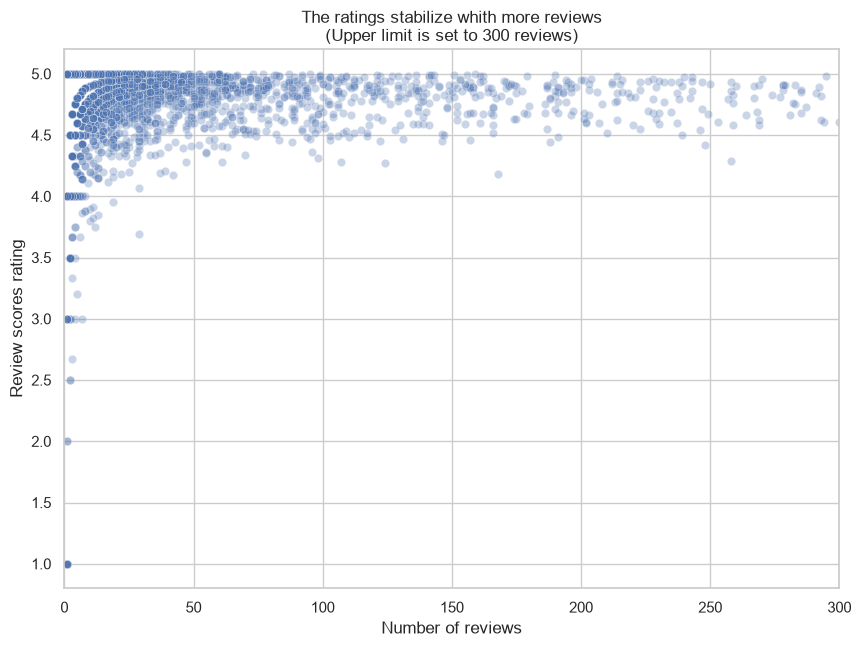

In [45]:
fig, ax = plt.subplots(figsize=(10, 7))

sns.scatterplot(data=only_has_reviews, x="number_of_reviews", y="review_scores_rating", alpha=0.3, ax=ax)

ax.set_xlim(0, 300)
ax.set_title("The ratings stabilize whith more reviews\n(Upper limit is set to 300 reviews)")
ax.set_xlabel("Number of reviews")
ax.set_ylabel("Review scores rating")

plt.show()